# Домашнее задание 1

**Студент:** Ильин Евгений  
**Группа:** А05-606

## Требования к выполнению

Сдайте один файл `.ipynb` с кодом, результатами выполнения и обоснованными ответами.
<div style="color: #d00000; font-size: 16px; font-weight: 800; line-height: 1.3; margin-bottom: 24px;">ВНИМАНИЕ!<br>ПОСЛЕ ЗАГРУЗКИ НОУТБУКА В БОТА ЕГО НЕЛЬЗЯ ИЗМЕНЯТЬ ИЛИ ПЕРЕЗАПУСКАТЬ.</div>

Используйте предоставленные разбиения данных. Модели и преобразования обучайте
только на train, гиперпараметры выбирайте по validation. Test используйте
для финальной оценки после фиксации модели и её настроек; изменять решение
по результатам test нельзя. Перед оценкой на test не переобучайте модель
на train + validation.

## Зависимости

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown

SEED = 42
plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.22,
    "font.size": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
pd.set_option("display.max_columns", 12)
pd.set_option("display.width", 130)
pd.set_option("display.precision", 4)
sklearn.set_config(display="text")
print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | "
      f"pandas {pd.__version__} | scikit-learn {sklearn.__version__} | "
      f"matplotlib {matplotlib.__version__}")

/home/evgen/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


Python 3.10.12 | NumPy 1.26.4 | pandas 2.2.3 | scikit-learn 1.5.2 | matplotlib 3.10.3


## Задача 1. Регуляризация линейной регрессии

Признаки и целевая переменная центрированы. Пусть $X\in\mathbb{R}^{n\times d}$ и

$$\frac{X^\top X}{n}=I_d,\qquad \frac{X^\top y}{n}=c.$$

При $\lambda>0$ заданы функции:

$$L_{\mathrm{OLS}}(w)=\frac{1}{2n}\|y-Xw\|_2^2,$$
$$L_{\mathrm{Ridge}}(w)=\frac{1}{2n}\|y-Xw\|_2^2+\frac{\lambda}{2}\|w\|_2^2,$$
$$L_{\mathrm{Lasso}}(w)=\frac{1}{2n}\|y-Xw\|_2^2+\lambda\|w\|_1.$$

1. Найдите и обоснуйте решения всех трёх задач минимизации.
2. В этом пункте условие $X^\top X/n=I_d$ не предполагается. Для произвольной фиксированной матрицы центрированных признаков докажите, что с ростом $\lambda>0$ евклидова норма оптимального вектора коэффициентов Ridge не возрастает, а обучающая ошибка $\|y-X\hat w_\lambda\|_2^2$ не убывает.
3. Столбец $X_j$ умножили на $a=10$, остальные столбцы не меняли. Как изменить коэффициент, чтобы сохранить предсказания? Как изменятся штрафы для того же предсказания? Сохранится ли оптимальное предсказание OLS? Объясните связь этого преобразования со стандартизацией признаков.
4. Если добавить свободный член $b$, следует ли включать его в штраф? Обоснуйте ответ.

#define $L_1 = L_{OLS}, \, L_2 = L_{Ridge}, \, L_3 = L_{Lasso}$

### 1.1
Так как работаем в поле вещественных чисел, то имеем следующее
$$
2nL_1 = \langle y - Xw, y - Xw \rangle = \langle y, y\rangle + \langle w, X^TXw\rangle - 2\langle X^T y, w\rangle, \\

\nabla_w nL_1 = X^TXw - X^Ty = 0 \Rightarrow \\ 
$$

Решение задачи линейной системы существует всегда (ранг расширенной матрицы совпадает с рангом матрицы системы), при этом $$ X^T X \in \mathbb{R}^{d\times d}, rank{X^TX} < \min(n, d), $$ так что если матрица МНК не вырождена, то решение к тому же единственно и дается формулой:
$$
{ w = (X^TX)^{-1} Xy = X^{\dagger}y }
$$
Второе равенство выделяет решение с минимальной евклидовой нормой при неоднозначной разрешимости. В каждом случае решение есть искомый минимум

$$
2nL_2 = \langle y - Xw, y - Xw \rangle + n\lambda \langle w, w \rangle = const + \langle w, X^TXw\rangle - 2\langle X^T y, w\rangle + n\lambda\langle w, w\rangle,\\

\nabla_w nL_1 = X^TXw - X^Ty + n\lambda w = 0 \Rightarrow \\ 
$$

$$ (X^TX + n\lambda I_d) w = X^Ty $$

При любом $\lambda > 0$ матрица является обратимой и решение (а значит и точка минимума) дается формулой

$$ { w = (X^TX + n\lambda I_d)^{-1} X^Ty.}  $$

Третье не решается в общем виде: необходимое условие минимума: $0\in \frac1n X^T(Xw-y) + \lambda\,\partial\|w\|_1$

Если $X^TX = nI_d$, то (как минимум n > d) имеем $L_3 = \frac12 \langle c, c\rangle + \frac{1}{2}\langle w, w\rangle - \langle w, c\rangle + \lambda \|w\|_1 $ 

$L_3 = \sum_{i = 1}^n (\frac{1}{2}  (w_i - c_i)^2 + \lambda |w_i| + ) \rightarrow \min \Leftrightarrow (\frac12|c_i - w_i|^2 + \lambda |w_i|) \rightarrow \min \forall i = 1 .. n.$ 

$$ \frac12|c_i - w_i|^2 + \lambda |w_i| = \frac12 c_i^2 - c_i w_i + w_i^2 + \lambda |w_i| $$

$$ \min L_3 = \min\left( \min_{w_i \in (-\infty, 0]}( \frac12 c_i^2 - (c_i + \lambda) w_i +  \frac12 w_i^2), \min_{w_i \in [0, +\infty)}( \frac12 c_i^2 - (c_i - \lambda) w_i +  \frac12 w_i^2)  \right)$$

Вершины парабол даются формулами: $w^{\mp}_i = (c_i \pm \lambda)$

При $c_i < -\lambda$ имеем $w_i = c_i + \lambda$

При $c_i >  \lambda$ имеем $w_i = c_i - \lambda$

Иначе $w_i = 0$ (так как в этом случае сужения парабол на своих областях опередления не имеют вершин, то есть точка их минимума находится на границе области)

Итого: $ nw = sign(X^Ty) \cdot (max(|X^Ty|, \lambda \mathbf{1}) - \lambda \mathbf{1}), $ где функции понимаются поэлементно

### 1.2

Пусть $X = U \Sigma V^T $ -- сингулярное разложение для действительной матрицы, тогда $w = V D U^T y$, где $D = (\Sigma^2 + b\lambda I_d)^{-1}\Sigma \Rightarrow$

$\|w\|_2 = \sum_{i = 1}^d f_i(\lambda) |(U^Ty)_i|^2,$ где $f_i(\lambda) = \frac{\sigma_i}{\sigma_i^2 + n\lambda}$ -- нестрого мотононно убывающая функция. Значит, что и норма вектора несторого убывает (видно покомпонентно)

Аналогично $Xw = U \Sigma^2 (\Sigma^2 + n\lambda I_d)^{-1} U^T y, ,\ \Rightarrow \, \|y - Xw\| = const - \langle A(\lambda) b, (2 I_d - A(\lambda)) b  \rangle, $ где $b = U^Ty, \, A(\lambda) = \Sigma^2 (\Sigma^2 + n\lambda I_d)^{-1}$. Таким образом

$$ \|y - Xw\| = const - \sum_{i=1}^d g_i(\lambda) |b_i|^2, \, g_i(\lambda) = \frac{\sigma_i^2 (\sigma_i^2 + 2 n \lambda)}{(\sigma_i^2 + n\lambda)^2} = 1 - \frac{n^2 \lambda^2}{(\sigma_i^2 + n\lambda)^2}  $$

Так как $g(\lambda)$ нестрого мотонотнно убывает, то и сумма тоже $\Rightarrow$ ошибка предсказания нестрого монотонно растет 

### 1.3

Как изменить коэффициент, чтобы сохранить предсказания? -> если я правильно понял, в чем вопрос, то изменить так: $w_j -> w_j / a$

Как изменятся штрафы для того же предсказания?
Сохранится ли оптимальное предсказание OLS? 
Объясните связь этого преобразования со стандартизацией признаков.

### 1.4

<Ваше решение>

## Задача 2. Метрики классификации и порог решения

Положительный класс — $y=1$. Для объектов заданы оценки вероятности $p(x)\in[0,1]$.
Правило классификации: $\hat y=1$, если $p(x)\geq t$, иначе $\hat y=0$.

1. На фиксированной конечной выборке, содержащей оба класса, исследуйте монотонность recall, precision и accuracy как функций порога $t$. Утверждения обоснуйте доказательствами или контрпримерами. Precision рассматривайте при наличии положительных предсказаний.
2. Стоимость верного решения равна 0, ложноположительного — $c_{FP}>0$, ложноотрицательного — $c_{FN}>0$. В этом пункте считайте $p(x)=P(y=1\mid x)$ истинной условной вероятностью. Выведите порог, минимизирующий ожидаемую стоимость ошибки. Обязан ли он минимизировать фактическую стоимость ошибок на любой конечной выборке? Докажите утверждение или приведите контрпример.
3. Пусть $p(x)=\sigma(w^\top x+b)$, где $\sigma(z)=1/(1+e^{-z})$. Какой порог на $z=w^\top x+b$ соответствует порогу $0<t<1$? При каких условиях порог из пункта 2 применим к прогнозам обученной модели?

### 2.1

<Ваше решение>

### 2.2

<Ваше решение>

### 2.3

<Ваше решение>

## Задача 3. Регрессия

Используйте набор данных `Diabetes`: 442 наблюдения, 10 признаков и численный
показатель прогрессирования диабета через год. Признаки: `age` — возраст,
`sex` — пол, `bmi` — индекс массы тела, `bp` — среднее артериальное давление,
`s1`–`s6` — лабораторные показатели.

Рассматриваются OLS — линейная регрессия методом наименьших квадратов,
Ridge — линейная регрессия с L2-регуляризацией и Lasso — с L1-регуляризацией.
В качестве базовой модели используется `DummyRegressor`, предсказывающий
среднее значение целевой переменной на обучающей выборке.

Данные загружаются с `scaled=False`. Разбиение train / validation / test —
приблизительно 60 / 20 / 20%. Финальная оценка на test выполняется в пункте 3.5.

[Описание данных](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html).

In [82]:
from IPython.display import Markdown as reg_Markdown
from sklearn.datasets import load_diabetes as reg_load_diabetes
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    Lasso,
)
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split as reg_train_test_split
from sklearn.pipeline import Pipeline as reg_Pipeline
from sklearn.preprocessing import StandardScaler as reg_StandardScaler

reg_dataset = reg_load_diabetes(as_frame=True, scaled=False)
reg_X_train, reg_X_holdout, reg_y_train, reg_y_holdout = reg_train_test_split(
    reg_dataset.data, reg_dataset.target, test_size=0.4, random_state=SEED
)
reg_X_valid, reg_X_test, reg_y_valid, reg_y_test = reg_train_test_split(
    reg_X_holdout, reg_y_holdout, test_size=0.5, random_state=SEED
)
del reg_dataset, reg_X_holdout, reg_y_holdout

def reg_rmse(y_true, y_pred):
    return float(np.sqrt(reg_mean_squared_error(y_true, y_pred)))

print(f"Train: {len(reg_y_train)}; validation: {len(reg_y_valid)}; "
      f"test: {len(reg_y_test)} наблюдений.")

# посмотрим на то как выглядит таблица датасета
display(reg_X_train)
# print(reg_y_train)


Train: 265; validation: 88; test: 89 наблюдений.


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
249,45.0,1.0,32.0,110.0,224.0,134.2,45.0,5.0,5.4116,93.0
250,67.0,1.0,31.6,116.0,179.0,90.4,41.0,4.0,5.4723,100.0
59,66.0,2.0,24.0,98.0,236.0,146.4,58.0,4.0,5.0626,96.0
111,54.0,1.0,26.8,87.0,206.0,122.0,68.0,3.0,4.3820,80.0
204,79.0,2.0,27.0,103.0,169.0,110.8,37.0,5.0,4.6634,110.0
...,...,...,...,...,...,...,...,...,...,...
106,22.0,1.0,19.3,82.0,156.0,93.2,52.0,3.0,3.9890,71.0
270,50.0,2.0,29.2,119.0,162.0,85.2,54.0,3.0,4.7362,95.0
348,57.0,1.0,24.5,93.0,186.0,96.6,71.0,3.0,4.5218,91.0
435,45.0,1.0,24.2,83.0,177.0,118.4,45.0,4.0,4.2195,82.0


### 3.1

На train проверьте пропуски, повторяющиеся строки и диапазоны признаков.
Постройте диаграмму `bmi`–`target` и вычислите корреляции между признаками.

1. Сравните численные масштабы признаков.
2. Как интерпретировать числовые значения `sex`? Достаточно ли одного столбца для представления этого признака в линейной модели со свободным членом?
3. Найдите тесно коррелирующую пару признаков. Как такая связь влияет на интерпретацию коэффициентов линейной модели?
4. Можно ли сделать вывод о причинном влиянии `bmi` на ответ? Обоснуйте ответ.

Does have skips: False


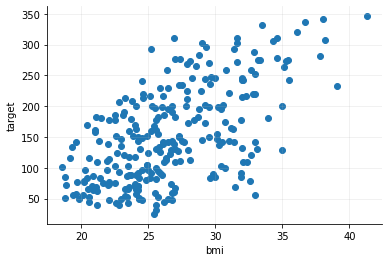

All corrs with target:
age    0.1898
sex    0.0425
bmi    0.6071
bp     0.4345
s1     0.1786
s2     0.1545
s3    -0.3984
s4     0.4192
s5     0.5164
s6     0.3779
dtype: float64
All features correlations


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
age,1.0000,0.1556,0.1819,0.3252,0.2556,0.1981,-0.0215,0.1668,0.2773,0.2903
sex,0.1556,1.0000,0.1086,0.1978,0.0338,0.1145,-0.3327,0.3328,0.1504,0.1687
bmi,0.1819,0.1086,1.0000,0.3622,0.2476,0.2756,-0.4108,0.4715,0.4557,0.4204
bp,0.3252,0.1978,0.3622,1.0000,0.2572,0.1776,-0.1197,0.2301,0.3829,0.4026
s1,0.2556,0.0338,0.2476,0.2572,1.0000,0.8897,0.0698,0.5428,0.5203,0.3264
s2,0.1981,0.1145,0.2756,0.1776,0.8897,1.0000,-0.1731,0.6461,0.3023,0.2897
s3,-0.0215,-0.3327,-0.4108,-0.1197,0.0698,-0.1731,1.0000,-0.7263,-0.3830,-0.2704
s4,0.1668,0.3328,0.4715,0.2301,0.5428,0.6461,-0.7263,1.0000,0.6272,0.4048
s5,0.2773,0.1504,0.4557,0.3829,0.5203,0.3023,-0.3830,0.6272,1.0000,0.4664
s6,0.2903,0.1687,0.4204,0.4026,0.3264,0.2897,-0.2704,0.4048,0.4664,1.0000


Strongly correlated features (more than 0.5)


s1  s2    0.8897
s2  s4    0.6461
s4  s5    0.6272
s1  s4    0.5428
    s5    0.5203
s3  s4   -0.7263
dtype: float64

Scale of non normalizedf features


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6
min,19.0,1.0,18.6,62.0,110.0,41.6,22.0,2.00,3.4965,58.0
max,79.0,2.0,41.3,133.0,301.0,242.4,99.0,9.09,6.1070,124.0


In [64]:
# проверка пропусков в датасете
skips_mask = reg_X_train.isna().any()
print("Does have skips:", skips_mask.any())

# диаграмма bmi-target
plt.scatter(reg_X_train["bmi"], reg_y_train)
plt.xlabel("bmi")
plt.ylabel("target")
plt.show()
print("All corrs with target:", reg_X_train.corrwith(reg_y_train), sep='\n')

# вычисление корреляции признаков всех со всеми
corr = reg_X_train.corr()
print("All features correlations")
display(corr)
# сильная корреляция между признаками
mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
pairs = corr.where(mask).stack()
correlation_threshold = 0.5
pairs = pairs[pairs.abs() > correlation_threshold].sort_values(ascending=False)
print(f"Strongly correlated features (more than {correlation_threshold})", )
display(pairs)

# численные масштабы признаков
print("Scale of non normalizedf features")
reg_X_train.agg(["min", "max"])


### Интерпретация категориальной фичи sex

Думаю, что тут проблема завязана на перенумерации признаков: я могу поставить m = 1, f = 2, а могу наоборот. Модель долждна выдавать одно и то же предсказание вне зависимости от вложения категорий в числа. Нужно сравнить построенные модели: одна с одними вложением, другая с другим. Если первая из второй (и обратно) получается заменой компонент модели, то все хорошо: мы можем построить новую модель, которая будет давать те же предсказания. Если рассмотреть модель со свободным членом, то свойство выше верно, так что можно кодировать пол одним столбцом. Если свободного члена в модели нет по какой-то причине, то необходимо, чтобы результат вложения двух категорий различался знаком, тогда при замене вложения на противоположное можно получить те же результаты.

Как я понимаю, для трех признаков такое уже не прокатывает и надо делать one hot embedding

### Линейная зависимость признаков

Линейная зависимость признаков s1 и s2 может сказаться на росте коэффициентов в линейной модели. У честно линенйно-зависимых признаков (учловимся, что в матрице есть столбце из единиц) в матрице фичей будет ненулеваое ядро: существуют вектора из коэффициентов, добавление которых просто не влияет на предсказание модели. Если признаки сильно скоррелированы, то всюду выже в рассуждении надо добавить слово "почти", и мы получим просто слабую устойчивость решения к вектору target. Формально у матрицы $X^TX$ будет большое число обусловленности, что и будет давать обсуждаемую неустойчивость (это можно показать через вариационное тождество для собственных значений матрицы $X^TX$).

### Причинная связь bmi с target

Наверное по одной корреляции не следует говорить о причинной связи, но если она есть у всех признаков, то у bmi сильнее остальных (это видно по корреляции). 

### 3.2

Обучите на train `DummyRegressor(strategy="mean")` и `LinearRegression` (OLS).
Для OLS используйте `Pipeline` со `StandardScaler`.
Представьте RMSE обеих моделей на validation в таблице. Сохраните обученные модели.

$$\operatorname{RMSE}=\sqrt{\frac1m\sum_{i=1}^{m}(y_i-\hat y_i)^2}.$$

Интерпретируйте сравнение с Dummy. Объясните, почему среднее для Dummy
и параметры scaler должны вычисляться по train.

In [77]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# 1. Создаем модели
dummy = DummyRegressor(strategy="mean")

ols = Pipeline([
    ("scaler", StandardScaler()),
    ("regressor", LinearRegression(fit_intercept=True))
])

# 2. Обучаем модели на train
dummy.fit(reg_X_train, reg_y_train)
ols.fit(reg_X_train, reg_y_train)

# 3. Предсказания на validation
y_pred_dummy = dummy.predict(reg_X_valid)
y_pred_ols = ols.predict(reg_X_valid)

# 4. Вычисляем RMSE
rmse_dummy = np.sqrt(mean_squared_error(reg_y_valid, y_pred_dummy))
rmse_ols = np.sqrt(mean_squared_error(reg_y_valid, y_pred_ols))

# 5. Создаем таблицу результатов
results = pd.DataFrame({
    "Model": ["DummyRegressor", "LinearRegression (OLS)"],
    "RMSE": [rmse_dummy, rmse_ols]
})

display(results)

,Model,RMSE
0,DummyRegressor,76.1614
1,LinearRegression (OLS),49.1497


In [ ]:
# 6. Допустим я случайно обучил dummy на validation
ultra_dummy = DummyRegressor(strategy="mean")
ultra_dummy.fit(reg_X_valid, reg_y_valid)
y_pred_dummy = ultra_dummy.predict(reg_X_valid)
rmse_ultra_dummy = np.sqrt(mean_squared_error(reg_y_valid, y_pred_dummy))
stupid_results = pd.DataFrame({
    "Model": ["DummyRegressor", "LinearRegression (OLS)"],
    "RMSE": [rmse_ultra_dummy, rmse_ols]
})
display(stupid_results)

,Model,RMSE
0,DummyRegressor,75.9271
1,LinearRegression (OLS),49.1497


Ну стало немнжко получше, в результате данные из validation утекли в обучающую выборку. Для линейной регрессии предсказания не должны измениться, поскольку стандартизация признаков просто изменит коэффициентв в модели, но класс моделей не поменяется.

### 3.3

Создайте копии train и validation, умножив только `bmi` на `1000`.
Сравните четыре варианта:

- OLS без стандартизации;
- OLS со `StandardScaler`;
- `Ridge(alpha=1000)` без стандартизации;
- `Ridge(alpha=1000)` со `StandardScaler`.

Для каждого варианта обучите отдельные модели на исходных и преобразованных
данных. Используйте validation в тех же единицах, что и соответствующий train.

Постройте четыре диаграммы: по горизонтали — прогноз на исходных данных,
по вертикали — прогноз после преобразования для того же объекта.
Добавьте диагональ $y=x$ и одинаковый масштаб осей внутри каждой панели.

1. В каких вариантах изменились прогнозы? Объясните результаты.
2. Как преобразование признака связано с коэффициентом при `bmi` и штрафом Ridge?
3. Какова роль стандартизации в этом эксперименте? Гарантирует ли она снижение ошибки при фиксированном `alpha`?

RMSE for OLS 49.14969247001352 49.14969247001368
RMSE for OLS + scaler 49.14969247001349 49.149692470013484
RMSE for Ridge 52.24320600184006 52.32559120917451
RMSE for Ridge + scaler 61.959387183584575 61.959387183584575


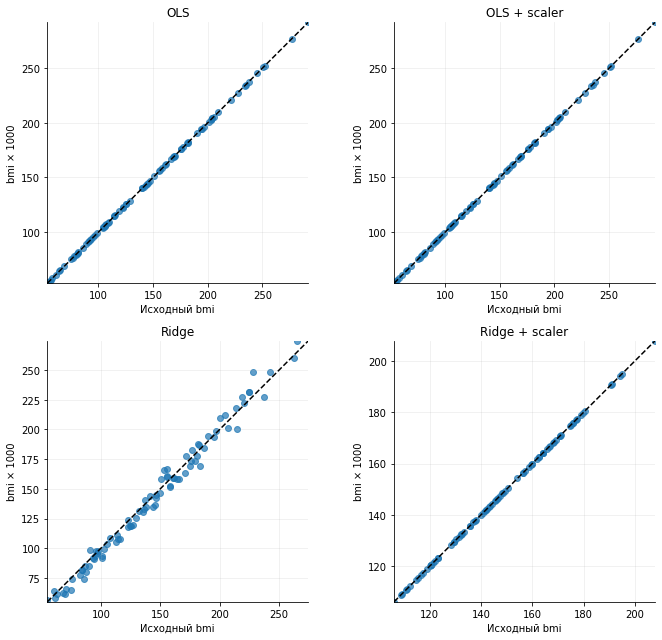

In [100]:
reg_X_train_bmi = reg_X_train.copy()
reg_X_valid_bmi = reg_X_valid.copy()
reg_X_train_bmi["bmi"] *= 1000
reg_X_valid_bmi["bmi"] *= 1000

reg_33_specs = {
    "OLS": lambda: LinearRegression(),
    "OLS + scaler": lambda: Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression()),
    ]),
    "Ridge": lambda: Ridge(alpha=1000),
    "Ridge + scaler": lambda: Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=1000)),
    ]),
}

reg_33_models = {}
fig, axes = plt.subplots(2, 2, figsize=(10, 9))
for ax, (name, make_model) in zip(axes.flat, reg_33_specs.items()):
    model_original = make_model().fit(reg_X_train, reg_y_train)
    model_scaled = make_model().fit(reg_X_train_bmi, reg_y_train)
    pred_original = model_original.predict(reg_X_valid)
    pred_scaled = model_scaled.predict(reg_X_valid_bmi)
    print("RMSE for", name, np.sqrt(mean_squared_error(pred_original, reg_y_valid)), np.sqrt(mean_squared_error(pred_scaled, reg_y_valid)))
    reg_33_models[name] = {"original": model_original, "bmi_x1000": model_scaled}

    limits = [min(pred_original.min(), pred_scaled.min()),
              max(pred_original.max(), pred_scaled.max())]
    ax.scatter(pred_original, pred_scaled, alpha=0.7)
    ax.plot(limits, limits, "--", color="black")
    ax.set(xlabel="Исходный bmi", ylabel="bmi × 1000",
           title=name, xlim=limits, ylim=limits)
    ax.set_aspect("equal", adjustable="box")
plt.tight_layout()
plt.show()

### Описание результатов

Результаты изменились только для Ridge без scaler.
1. OLS -> OLS на новых фичах == замена координат для минимизации функционала => значение минимума функции не изменилось (случилось предобуславливание). Более того OLS и OLS + scaler всегда будут давать отдно и тоже аналитическое решение, так как не меняется класс моделей с постоянным коэффициентом, а учитывая, что в нашем случае матрица невырождена и точное линейной регрессией находится точное решение, то и значение минимума останется на том же предсказании. 
2. Теперь если сравнить второй столбец на двух пачках данных, то понятно, что на самом деле на вход модели подается всегда одно и то же (что для OLS + scaler, что для Ridge + scaler, scaler перевел данные в одинаковое представление)
3. Ridge без скейлера: при изменерие фичи можно трактовать как изменение весового коэффициента при том же наборе фичей. При этом если во всех остальных случаях это преобразование можно трактовать как изменение системы координат, в котором записана функция, при этом без изменения вида функции, то здесь изменяется регуляризатор: коэиффициент при $\omega_j$ делится на 1е6, тогда и оптимальное решение изменяется.
4. При использовании модели линейной регрессии стандартизация признаков гаратирует, что для этой модели будет получаться ровно то же самое предсказание, что и при линейно преобразованных признаках (по воле эскспериментатора, случая или измерительного прибора). Иначе без скейлинга будут получаеться каждый раз разные результаты при использовании линейной регрересси с регуляризацией. Ну и в данном случае использования скейлера при Ridge увеличило RMSE, однако это скорее связано с тем, что надо коэффициент регуляризации подбирать по-умному.

In [92]:
# Мне стало интересно посмотреть на число обусловленности при скейлинге
def singular_values(X):
    X_array = np.asarray(X, dtype=float)
    X_with_intercept = np.column_stack((
        np.ones(X_array.shape[0]),
        X_array))

    X_scaled = StandardScaler().fit_transform(X_array)

    X_with_intercept_scaled = np.column_stack((
        np.ones(X_scaled.shape[0]),
        X_scaled))
    
    singular_original = np.linalg.svd(
        X_with_intercept,
        compute_uv=False
    )
    singular_scaled = np.linalg.svd(
        X_with_intercept_scaled,
        compute_uv=False
    )

    return singular_original, singular_scaled

sv_original, sv_scaled = singular_values(reg_X_train)

print("Исходная матрица:")
print(sv_original)

print("Стандартизованная матрица:")
print(sv_scaled)

Исходная матрица:
[4.43207761e+03 4.09384394e+02 2.55332949e+02 1.84634752e+02
 1.57924798e+02 1.27646850e+02 6.19938274e+01 9.98029960e+00
 6.76991072e+00 4.39544690e+00 6.36564664e-01]
Стандартизованная матрица:
[32.48052331 19.98372247 18.22009406 16.2788206  15.81216187 13.29177022
 12.25657224 12.0557785  10.8778561   4.53668688  1.58882237]


### 3.4

На исходных признаках обучите модели в `Pipeline` со `StandardScaler`:

- Ridge: `alpha = [0.1, 1, 10, 100, 1000, 10000]`;
- Lasso: `alpha = [0.01, 0.1, 1, 3, 10, 30, 100]`, `max_iter=20000`.

Для каждого значения сохраните модель, коэффициенты, train RMSE и validation RMSE.
Постройте рисунок из четырёх панелей: в верхнем ряду — зависимости ошибок
от `alpha` для двух моделей, в нижнем — зависимости их коэффициентов от `alpha`.
Используйте логарифмическую ось `alpha` и линию нуля на графиках коэффициентов.

1. Как регуляризация влияет на train RMSE и validation RMSE? Объясните форму полученных кривых.
2. Проверьте по графикам утверждение: «При усилении Ridge-регуляризации каждый коэффициент не возрастает по модулю». Объясните результат и его связь с пунктом 1.2. Сравните поведение с Lasso: есть ли нулевые коэффициенты и что можно заключить о соответствующих признаках?
3. По документации [Ridge](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html) и [Lasso](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html) установите связь `alpha` с $\lambda$ из задачи 1. Можно ли сравнивать силу двух видов регуляризации по одинаковому числу `alpha`?
4. Интерпретируйте знак и величину коэффициента `bmi` у Lasso при `alpha=1`. Можно ли считать модуль коэффициента мерой важности признака? Обоснуйте ответ.

,model,alpha,train_rmse,valid_rmse
0,Ridge,0.10,54.2851,49.1556
1,Ridge,1.00,54.2966,49.2033
2,Ridge,10.00,54.3951,49.3731
3,Ridge,100.00,55.4401,50.8149
4,Ridge,1000.00,64.4421,61.9594
5,Ridge,10000.00,74.7826,73.4071
6,Lasso,0.01,54.2853,49.1575
7,Lasso,0.10,54.3023,49.2036
8,Lasso,1.00,54.4733,49.5254
9,Lasso,3.00,55.0220,50.7262


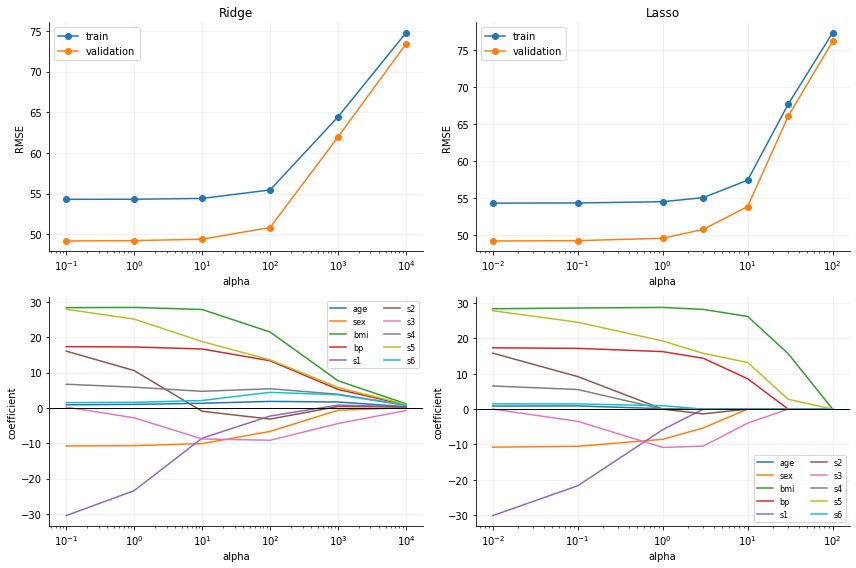

In [112]:
ridge_alphas = [0.1, 1, 10, 100, 1000, 10000]
lasso_alphas = [0.01, 0.1, 1, 3, 10, 30, 100]
reg_models = {"Ridge": {}, "Lasso": {}}
reg_rows = []
reg_coefs = {"Ridge": [], "Lasso": []}

for model_name, alphas in [("Ridge", ridge_alphas), ("Lasso", lasso_alphas)]:
    for alpha in alphas:
        estimator = Ridge(alpha=alpha) if model_name == "Ridge" else Lasso(alpha=alpha, max_iter=20000)
        model = Pipeline([
            ("scaler", StandardScaler()),
            ("model", estimator),
        ]).fit(reg_X_train, reg_y_train)
        reg_models[model_name][alpha] = model
        reg_coefs[model_name].append(model.named_steps["model"].coef_)
        reg_rows.append({
            "model": model_name,
            "alpha": alpha,
            "train_rmse": np.sqrt(mean_squared_error(reg_y_train, model.predict(reg_X_train))),
            "valid_rmse": np.sqrt(mean_squared_error(reg_y_valid, model.predict(reg_X_valid))),
        })

reg_results = pd.DataFrame(reg_rows)
display(reg_results)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for column, (model_name, alphas) in enumerate([("Ridge", ridge_alphas), ("Lasso", lasso_alphas)]):
    subset = reg_results[reg_results["model"] == model_name]
    axes[0, column].plot(subset["alpha"], subset["train_rmse"], marker="o", label="train")
    axes[0, column].plot(subset["alpha"], subset["valid_rmse"], marker="o", label="validation")
    axes[0, column].set(xscale="log", xlabel="alpha", ylabel="RMSE", title=model_name)
    axes[0, column].legend()

    axes[1, column].plot(alphas, np.asarray(reg_coefs[model_name]))
    axes[1, column].axhline(0, color="black", linewidth=1)
    axes[1, column].set(xscale="log", xlabel="alpha", ylabel="coefficient")
    axes[1, column].legend(reg_X_train.columns, ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

### Интерпретация результатов 

1. Обучающая ошибка не убывает, а норма вектора коэффициентов не возрастает для Ridge (как по теории и есть). Для Lasso постепенно зануляются коэффициенты, с ростом коэффициента регуляризации мы все больше оптимизируем регуляризатор, который есть выпуклая оболочка функции "количество ненулевых компонент вектора из R^n".
2. Это неправда. Lasso может отбирать наиболее информацтивные признаки.
3. `alpha` = $\lambda n$ для Ridge, для Lasso равенство. Можно ли сравнивать силу двух видов регуляризации по одинаковому числу `alpha` -- ну надо понять что такое "сила" регуляризации, но ответ нет: регуляризации по-разному действуют.

4.1. Интерпретируйте знак и величину коэффициента `bmi` у Lasso при `alpha=1` -> величина коэффициента -- чувствтельность к изменению, а знак совпадает со знаком коэффициента корреляции.

4.2. Можно ли считать модуль коэффициента мерой важности признака? -> в некотором смысле можно поскольку формально у этого признака наибольшая чувствительность к изменению. Знак совпадает со знаком корреляции.

### 3.5

По результатам 3.2 и 3.4 выберите OLS или одну из моделей Ridge/Lasso
со `StandardScaler`. Зафиксируйте и обоснуйте выбор до обращения к test.

Вычислите test RMSE выбранной обученной модели. Постройте график фактических
значений против прогнозов с диагональю либо остатков против прогнозов с линией нуля.

Интерпретируйте график и укажите ограничение модели или проведённого эксперимента.

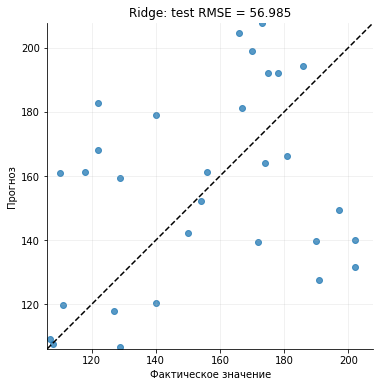

In [119]:
reg_test_pred = reg_models["Ridge"][0.1].predict(reg_X_test)
reg_test_rmse = np.sqrt(mean_squared_error(reg_y_test, reg_test_pred))

plt.figure(figsize=(6, 6))
plt.scatter(reg_y_test, reg_test_pred, alpha=0.75)
plt.plot(limits, limits, "--", color="black")
plt.xlim(limits)
plt.ylim(limits)
plt.gca().set_aspect("equal", adjustable="box")
plt.xlabel("Фактическое значение")
plt.ylabel("Прогноз")
plt.title(f"Ridge: test RMSE = {reg_test_rmse:.3f}")
plt.show()

## Задача 4. Классификация

Используйте набор Wisconsin Diagnostic Breast Cancer. Он содержит 30 числовых
характеристик клеточных ядер. Во всех пунктах используйте только `mean radius`
и `mean texture`. Целевая переменная перекодирована:
`1 = malignant` (злокачественная опухоль), `0 = benign` (доброкачественная опухоль).

Рассматриваются четыре метода:

- логистическая регрессия — модель вероятности класса с сигмоидой от линейной комбинации признаков;
- kNN — классификация по меткам ближайших соседей;
- SVM с RBF-ядром — метод опорных векторов с гауссовым ядром;
- дерево решений — последовательность разбиений по значениям признаков.

Стратифицированное разбиение train / validation / test — 60 / 20 / 20%.
Финальная оценка на test выполняется в пункте 4.5.

[Описание данных](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html).

In [ ]:
from IPython.display import Markdown as cls_Markdown
from sklearn.datasets import load_breast_cancer as cls_load_data
from sklearn.dummy import DummyClassifier as cls_DummyClassifier
from sklearn.linear_model import LogisticRegression as cls_LogisticRegression
from sklearn.neighbors import KNeighborsClassifier as cls_KNeighborsClassifier
from sklearn.svm import SVC as cls_SVC
from sklearn.tree import DecisionTreeClassifier as cls_DecisionTreeClassifier
from sklearn.pipeline import Pipeline as cls_Pipeline
from sklearn.preprocessing import StandardScaler as cls_StandardScaler
from sklearn.model_selection import train_test_split as cls_train_test_split
from sklearn.metrics import (
    balanced_accuracy_score as cls_balanced_accuracy_score,
    precision_score as cls_precision_score,
    recall_score as cls_recall_score,
    confusion_matrix as cls_confusion_matrix,
    ConfusionMatrixDisplay as cls_ConfusionMatrixDisplay,
)

cls_data = cls_load_data(as_frame=True)
cls_features = ["mean radius", "mean texture"]
cls_X = cls_data.data[cls_features].copy()
cls_y = (cls_data.target == 0).astype(int).rename("malignant")
cls_X_dev, cls_X_test, cls_y_dev, cls_y_test = cls_train_test_split(
    cls_X, cls_y, test_size=0.20, stratify=cls_y, random_state=SEED
)
cls_X_train, cls_X_val, cls_y_train, cls_y_val = cls_train_test_split(
    cls_X_dev, cls_y_dev, test_size=0.25, stratify=cls_y_dev, random_state=SEED
)
assert set(cls_X_train.index).isdisjoint(cls_X_val.index)
assert set(cls_X_train.index).isdisjoint(cls_X_test.index)
assert set(cls_X_val.index).isdisjoint(cls_X_test.index)
print("Число объектов train / validation / test:",
      len(cls_X_train), len(cls_X_val), len(cls_X_test))

Функция `cls_plot_boundaries(models, titles=None, radius_multipliers=None, mark_errors=True)`
принимает словарь «название → обученная модель» и строит области предсказанных классов.
На графике отображаются train-объекты и, при `mark_errors=True`, ошибки validation.
`titles` задаёт подписи, `radius_multipliers` — множители радиуса на входе каждой модели.
Координаты графика соответствуют исходным единицам признаков.

In [ ]:
cls_colors = {0: "#2a788e", 1: "#c95a47"}
cls_names = {0: "benign (0)", 1: "malignant (1)"}
cls_low = cls_X_train.min() - 0.06 * (cls_X_train.max() - cls_X_train.min())
cls_high = cls_X_train.max() + 0.06 * (cls_X_train.max() - cls_X_train.min())
cls_xx, cls_yy = np.meshgrid(
    np.linspace(cls_low.iloc[0], cls_high.iloc[0], 180),
    np.linspace(cls_low.iloc[1], cls_high.iloc[1], 180),
)
cls_grid = pd.DataFrame({cls_features[0]: cls_xx.ravel(), cls_features[1]: cls_yy.ravel()})

def cls_draw_boundary(model, ax, title, radius_multiplier=1, mark_errors=True):
    grid = cls_grid.copy()
    grid[cls_features[0]] *= radius_multiplier
    pred = model.predict(grid).reshape(cls_xx.shape)
    ax.contourf(cls_xx, cls_yy, pred, levels=[-0.5, 0.5, 1.5],
                colors=[cls_colors[0], cls_colors[1]], alpha=0.19)
    if hasattr(model, "decision_function"):
        score = model.decision_function(grid).reshape(cls_xx.shape)
        ax.contour(cls_xx, cls_yy, score, levels=[0], colors="#333333", linewidths=1)
    else:
        ax.contour(cls_xx, cls_yy, pred, levels=[0.5], colors="#333333", linewidths=1)
    for label in [0, 1]:
        mask = cls_y_train == label
        ax.scatter(cls_X_train.loc[mask, cls_features[0]],
                   cls_X_train.loc[mask, cls_features[1]],
                   color=cls_colors[label], s=15, alpha=0.65, label=cls_names[label])
    if mark_errors:
        val = cls_X_val.copy()
        val[cls_features[0]] *= radius_multiplier
        wrong = model.predict(val) != cls_y_val
        ax.scatter(cls_X_val.loc[wrong, cls_features[0]], cls_X_val.loc[wrong, cls_features[1]],
                   color="black", marker="x", s=30, linewidths=1, label="ошибка validation")
    ax.set(xlabel=cls_features[0], ylabel=cls_features[1], title=title,
           xlim=(cls_low.iloc[0], cls_high.iloc[0]),
           ylim=(cls_low.iloc[1], cls_high.iloc[1]))


def cls_plot_boundaries(models, titles=None, radius_multipliers=None, mark_errors=True):
    # models: словарь «название → обученная модель»; функция ничего не обучает.
    if not 1 <= len(models) <= 4:
        raise ValueError("Передайте от одной до четырёх обученных моделей")
    titles = {} if titles is None else titles
    radius_multipliers = {} if radius_multipliers is None else radius_multipliers
    columns = min(2, len(models))
    rows = (len(models) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(5.5 * columns, 4 * rows),
                             sharex=True, sharey=True, squeeze=False)
    for ax, (name, model) in zip(axes.flat, models.items()):
        cls_draw_boundary(model, ax, titles.get(name, name),
                          radius_multiplier=radius_multipliers.get(name, 1),
                          mark_errors=mark_errors)
    for ax in list(axes.flat)[len(models):]:
        ax.set_visible(False)
    axes.flat[0].legend(fontsize=8)
    fig.suptitle("Точки — train" + ("; крестики — ошибки validation" if mark_errors else ""))
    fig.tight_layout()
    plt.show()

### 4.1

На train определите диапазоны двух признаков и доли классов.
Постройте диаграмму `mean radius` × `mean texture` с цветом по классу.

1. В каких областях ожидаете ошибки классификатора по этим двум признакам? Обоснуйте ответ.
2. Вычислите accuracy, recall класса 1 и balanced accuracy для правила «всегда класс большинства». Сравните информативность этих метрик.

В пунктах 4.2 и 4.5 основная метрика — balanced accuracy:
$\mathrm{BA}=(\mathrm{recall}_0+\mathrm{recall}_1)/2$.

<Ваше решение>

### 4.2

Сравните логистическую регрессию, kNN, SVM с RBF-ядром и дерево решений.
Самостоятельно выберите гиперпараметры для исследования и подберите их значения
по validation balanced accuracy. Для каждого метода исследуйте не менее трёх
значений хотя бы одного гиперпараметра, определяющего сложность или структуру
модели. Сохраните выбранную модель и представьте результаты сравнения.

Постройте границы выбранных моделей. Можно использовать функцию
`cls_plot_boundaries(models)`, передав словарь обученных моделей.

Отдельно исследуйте влияние глубины дерева на train и validation balanced accuracy.
Диапазон глубин выберите самостоятельно и представьте результаты на графике.

1. Обоснуйте выбор настроек и объясните различия форм границ четырёх моделей.
2. Выберите одну область ошибок validation и объясните её через форму границы.
3. Интерпретируйте зависимости метрик от глубины дерева.

<Ваше решение>

### 4.3

Создайте копии train и validation, умножив только `mean radius` на `100`.
На исходных и преобразованных данных обучите по одной версии:

- kNN с `n_neighbors=9` без стандартизации;
- kNN с `n_neighbors=9` и `StandardScaler`;
- дерева с `max_depth=3`, `random_state=SEED`.

Для каждого метода вычислите долю validation-объектов, у которых изменилась
предсказанная метка. Изобразите две границы kNN без стандартизации
в исходных координатах. При использовании `cls_plot_boundaries` передайте
`radius_multipliers={название_преобразованной_модели: 100}` и `mark_errors=False`.

Объясните результаты для каждого метода и роль масштаба признаков.

<Ваше решение>

### 4.4

Для обученной логистической регрессии из 4.2 получите оценки вероятности
класса 1 на validation. Для порога $t$ используйте правило $\hat y=1$ при $p(x)\ge t$.
Постройте зависимости precision и recall от порога на отрезке $[0,1]$.

Для порогов `0.2, 0.5, 0.8` составьте таблицу: precision, recall, FP, FN.
При отсутствии положительных предсказаний используйте `zero_division=0`.

1. Как зависят FP и FN от порога? Исследуйте монотонность precision и recall. Объясните смысл `zero_division=0`.
2. Какой из трёх порогов вы выберете, если пропуск класса 1 значительно дороже ложного срабатывания? Какие данные нужны для численного обоснования выбора?
3. Как изменение порога влияет на вероятностные оценки, ранжирование объектов и границу классификации?

<Ваше решение>

### 4.5

По validation balanced accuracy выберите одну из четырёх моделей с подобранными
в пункте 4.2 гиперпараметрами. Зафиксируйте и обоснуйте выбор до обращения к test. Используйте обычный `predict`.

Оцените на test выбранную модель и `DummyClassifier(strategy="most_frequent")`,
обученный на train. Представьте balanced accuracy, precision и recall класса 1
в таблице и постройте матрицу ошибок выбранной модели.
Для precision используйте `zero_division=0`.

1. Какие ошибки преобладают? Как соотносятся матрица ошибок и рассчитанные метрики?
2. Сравните test и validation balanced accuracy. Интерпретируйте различие.

<Ваше решение>

## Выводы

Сформулируйте выводы по работе, укажите ограничения экспериментов
и предложите дальнейшее исследование.

<Ваше решение>

## Документация

- [Линейные модели](https://scikit-learn.org/stable/modules/linear_model.html).
- [Pipeline](https://scikit-learn.org/stable/modules/compose.html#pipeline).
- [Метод ближайших соседей](https://scikit-learn.org/stable/modules/neighbors.html).
- [Деревья решений](https://scikit-learn.org/stable/modules/tree.html).
- [Метрики](https://scikit-learn.org/stable/modules/model_evaluation.html).